In [1]:
import matplotlib
import matplotlib.pyplot as plt
import pickle
import numpy as np
import os,sys
sys.path.append('..')
from H2_6_31G_8Qbit import H2_6_31G_8Qbit

∣NK⟩ Tip: log(ψ) ∈ ℜ → ψ = exp(logψ) ∈ ℜ₊ (real NN gives only positive wave-function).

H2 分子基本信息
HF energy = -0.99749729 Ha
Total electrons = (1, 1)
Total basis functions = 4
H₂ FCI 基准能量
E0 = -1.05434745 Ha  |  激发能: 0.0000 eV
E1 = -0.95790573 Ha  |  激发能: 2.6243 eV
E2 = -0.66895227 Ha  |  激发能: 10.4871 eV
E3 = -0.55140192 Ha  |  激发能: 13.6859 eV
E4 = -0.02803278 Ha  |  激发能: 27.9275 eV
E5 = -0.01450343 Ha  |  激发能: 28.2956 eV
E6 = -0.00518297 Ha  |  激发能: 28.5492 eV
E7 = 0.02397075 Ha  |  激发能: 29.3425 eV
E8 = 0.23432390 Ha  |  激发能: 35.0666 eV
E9 = 0.25720575 Ha  |  激发能: 35.6892 eV
E10 = 0.49958128 Ha  |  激发能: 42.2846 eV
E11 = 0.50024484 Ha  |  激发能: 42.3026 eV

HF reference state: [0 0 0 1 0 0 0 1]
single_edges: [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3), (4, 5), (4, 6), (4, 7), (5, 6), (5, 7), (6, 7)]


In [2]:
with open('./data/26-10-25-02-51_history_natural_gradient_H2_molecule_K6__realFFNN.pkl', 'rb') as f:
    data = pickle.load(f)

molecule = H2_6_31G_8Qbit(K=6)

/var/folders/8x/k_m4pmb11437ktb_r6tjzt2c0000gn/T/ipykernel_91581/2983078036.py:37: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


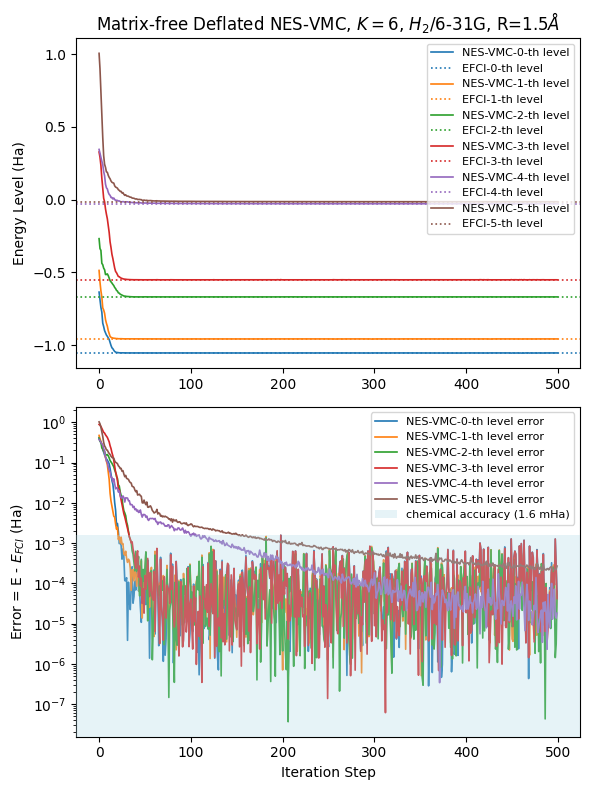

In [30]:
steps_history = data['steps']
lam_history = data['Energy_levels']
K=6
N_ITER = len(steps_history)
steps_arr = np.asarray(steps_history)
lam_arr = np.asarray(lam_history)

# ========== 配色定义：K个能级一一对应 ==========
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2", "#bcbd22", "#17becf"]  # 第0条、第1条能级的固定颜色
fci_targets = molecule.E_fcis[:6]

fig, axs = plt.subplots(2, 1, figsize=(6, 8))

# 子图0：λ_hat + FCI基准线，同能级同色
for k in range(K):
    axs[0].plot(steps_arr, lam_arr[:,k], lw=1.2, color=colors[k], label=f"NES-VMC-{k}-th level")
    axs[0].axhline(fci_targets[k], lw=1.2, linestyle=':', color=colors[k], label=f"EFCI-{k}-th level")
axs[0].set_ylabel("Energy Level (Ha)")
axs[0].set_title(r"Matrix-free Deflated NES-VMC, $K=6$, $H_2$/6-31G, R=1.5$\AA$")
axs[0].xaxis.set_major_formatter('{x:.0f}')
# axs[0].set_ylim(-0.05,0.4)
axs[0].legend(fontsize=8)

# 子图2：误差曲线，同能级复用上面的颜色
for k in range(K):
    error_k = np.abs(lam_arr[:,k] - fci_targets[k])
    axs[1].plot(steps_arr, error_k, lw=1.2, color=colors[k], label=f"NES-VMC-{k}-th level error")

axs[1].set_ylabel(r"Error = E - $E_{FCI}$ (Ha)")
axs[1].set_yscale("log")
axs[1].axhspan(0, 0.0016, facecolor="lightblue", alpha=0.3, zorder=10, label="chemical accuracy (1.6 mHa)")
axs[1].legend(fontsize=8)
axs[1].set_xlabel("Iteration Step")
fig.tight_layout()  # 放savefig之前！
fig.savefig("./H2-6-31G NES-VMC_K6.png", dpi=300)
fig.savefig("./H2-6-31G_NES-VMC_K6.pdf", bbox_inches="tight")
fig.show()
#fig.tight_layout()
